### Forecast data

In [144]:
import matplotlib.pyplot as plt
from cycler import cycler

# Define a muted palette that complements the poster colors
palette = [
    "#807098",  # Dusty purple
    "#526F91",  # Muted blue
    "#B18A32",  # Muted gold
    "#527B67",  # Sage green
    "#B66F58",  # Terracotta
    "#9C6481",  # Dusty rose
    "#49858A",  # Muted teal
    "#817565",  # Warm taupe
]

# Set the default color cycle for newly created plots
plt.rcParams["axes.prop_cycle"] = cycler(color=palette)

# Keep each model's color consistent regardless of plotting order
colors = dict(zip([
    "dmi_harmonie_arome_europe",
    "metno_nordic",
    "ecmwf_ifs025",
    "ecmwf_aifs025_single",
    "gfs_global",
    "ecmwf_ifs",
    "dmi_seamless",
    "gfs_seamless",
], palette))

colors["blend"] = "#35313D"

In [145]:
import numpy as np
import matplotlib.pyplot as plt
import solarpy
import pvlib
import pandas as pd

In [146]:
from pathlib import Path
import sys
import importlib
import scripts.functions as functions

importlib.reload(functions)

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from scripts.functions import get_dmi_ghi, resample_dmi_ghi_hourly, get_forecast_data, calculate_forecast_metrics, calculate_overall_metrics, our_blend_by_lead_time, our_blended_forecasts

In [147]:
#Get raw DMI measurements 
dmi_data = get_dmi_ghi(start="2025-11-09",end="2026-11-24", station="06019")

#Resample to hourly measurements
hourly_dmi = resample_dmi_ghi_hourly(dmi_data)

In [148]:


# #Get forecasts and match with measurements
# forecast_data = get_forecast_data(hourly_dmi, start="2026-11-09")

In [149]:
dmi_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 54649 entries, 2025-11-09 00:00:00+00:00 to 2026-11-24 00:00:00+00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ghi     54649 non-null  float64
dtypes: float64(1)
memory usage: 853.9 KB


## Filter night away using solpos

Find solar position, in order to filter night data points away

In [150]:
#Calculate solar position for forecast valid times
timestamps = pd.DatetimeIndex(pd.concat(forecast_data.values())["valid_time"].unique())

solpos = pvlib.solarposition.get_solarposition(
    timestamps,
    latitude=56.93,
    longitude=8.6412,
    method="nrel_numpy",
)

solar_elevation = solpos["apparent_elevation"]

#Only keeping the daylight hours
daylight_times = timestamps[solar_elevation.to_numpy() > 0]

df_forecast_day = {
    model: df[df["valid_time"].isin(daylight_times)].copy()
    for model, df in forecast_data.items()
}

It is easiest to work with one forecast model at a time. To avoid having the rows be specified by a multi-index, we can use ``.unstack()`` function for alle forecast models, such that the index becomes just the time and the lead time become the columns. And the resulting dataframes are stored in a dictionary for each model and can be plotted.

In [151]:
#Unstacking all forecast models
forecast_unstacked = {
    model: df.set_index(["valid_time", "lead_time_h"])["ghi_forecast"].unstack()
    for model, df in df_forecast_day.items()
}

We can add an overview of the data for each model, to help identify differences in forecast horizons and available data. 

In [152]:
for model, df in forecast_data.items():
    print(
        model,
        "| Forecasts:", len(df),
        "| Matched measurements:", df["ghi_measured"].notna().sum(),
        "| Max horizon:", df["lead_time_h"].max()
    )

dmi_harmonie_arome_europe | Forecasts: 18565 | Matched measurements: 0 | Max horizon: 56.0
metno_nordic | Forecasts: 18981 | Matched measurements: 0 | Max horizon: 57.0
ecmwf_ifs025 | Forecasts: 52189 | Matched measurements: 0 | Max horizon: 167.0
ecmwf_aifs025_single | Forecasts: 52189 | Matched measurements: 0 | Max horizon: 167.0
gfs_global | Forecasts: 52189 | Matched measurements: 0 | Max horizon: 167.0
ecmwf_ifs | Forecasts: 52189 | Matched measurements: 0 | Max horizon: 167.0
dmi_seamless | Forecasts: 52189 | Matched measurements: 0 | Max horizon: 167.0
gfs_seamless | Forecasts: 52189 | Matched measurements: 0 | Max horizon: 167.0


In [153]:
scores = calculate_forecast_metrics(
    forecast_unstacked,
    hourly_dmi,
)


In [154]:
# # Vis kun fejlmål baseret på mindst 30 sammenligninger.
# min_samples = 5

# scores_plot = scores.copy()

# scores_plot.loc[
#     scores_plot["n"] < min_samples,
#     ["rmse", "bias", "mae"],
# ] = np.nan

### 

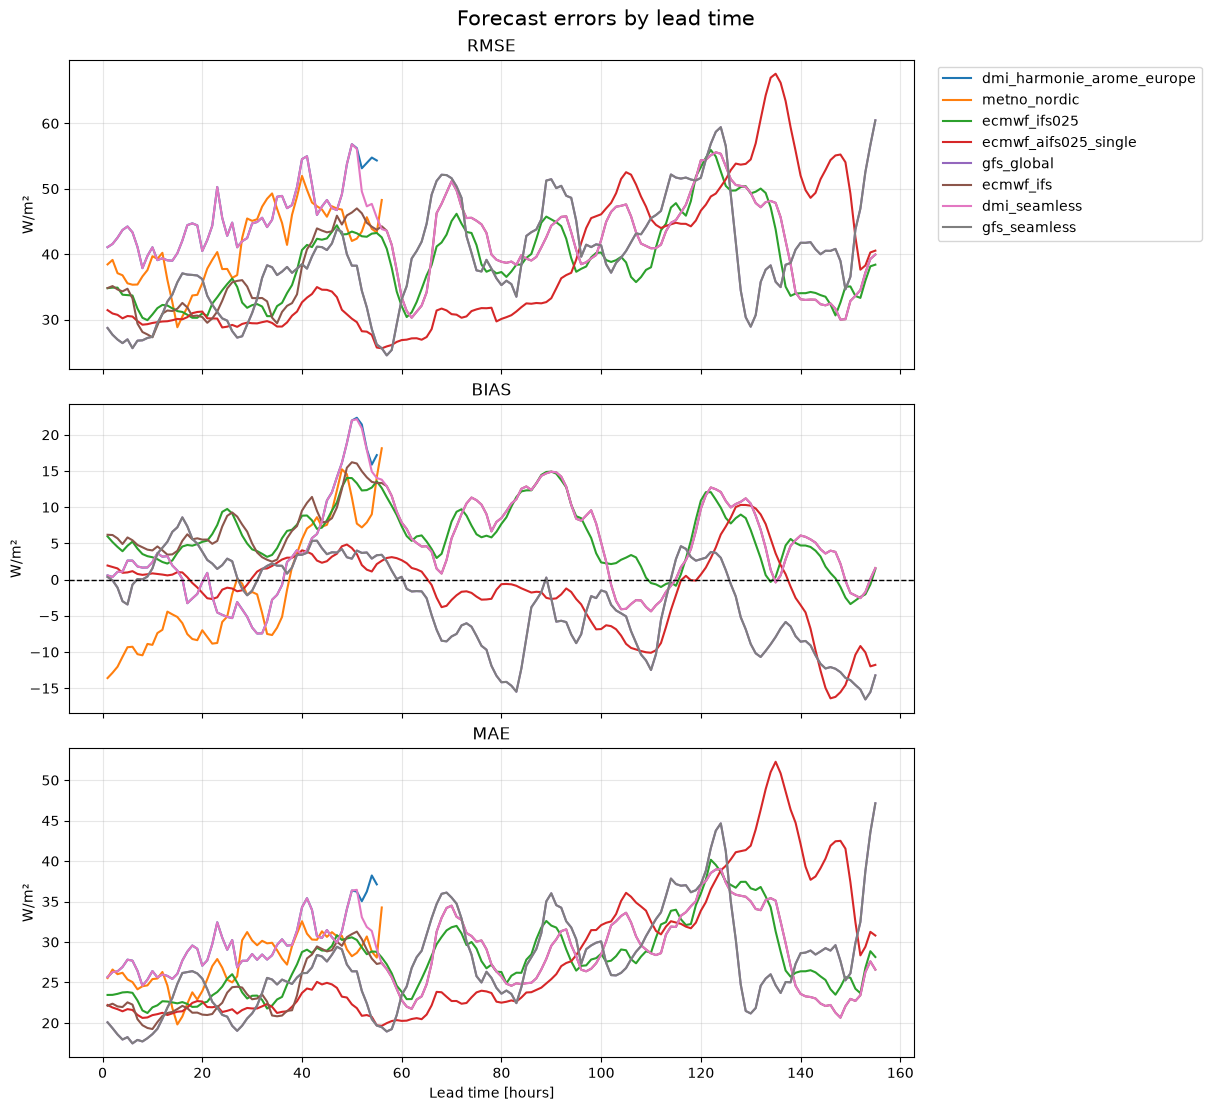

In [155]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scripts.functions as functions

# Select the forecasts to evaluate
evaluation_forecasts = forecast_unstacked
# evaluation_forecasts = matched_forecasts

# Recalculate the original metrics
scores = functions.calculate_forecast_metrics(
    evaluation_forecasts,
    hourly_dmi,
)

# Hide scores based on fewer than 30 matched pairs
scores_plot = scores.copy()
scores_plot.loc[
    scores_plot["n"] < 30,
    ["rmse", "bias", "mae"],
] = np.nan

# Assign consistent model colors for both figures
colors = {
    model: "black" if model == "blend" else plt.get_cmap("tab10")(i % 10)
    for i, model in enumerate(evaluation_forecasts)
}

# Create one subplot per metric
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 11),
    sharex=True,
    constrained_layout=True,
)

for ax, metric in zip(axes, ["rmse", "bias", "mae"]):

    # Plot each model across lead times
    for model, data in scores_plot.groupby("model", sort=False):
        data = data.sort_values("lead_time_h")
        ax.plot(
            data["lead_time_h"],
            data[metric],
            label=model,
            color=colors[model],
            linewidth=2.5 if model == "blend" else 1.5,
        )

    # Add labels, grid and the bias reference line
    ax.set_title(metric.upper())
    ax.set_ylabel("W/m²")
    ax.grid(alpha=0.3)

    if metric == "bias":
        ax.axhline(0, color="black", linestyle="--", linewidth=1)

axes[-1].set_xlabel("Lead time [hours]")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left")

fig.suptitle("Forecast errors by lead time", fontsize=15)
plt.show()

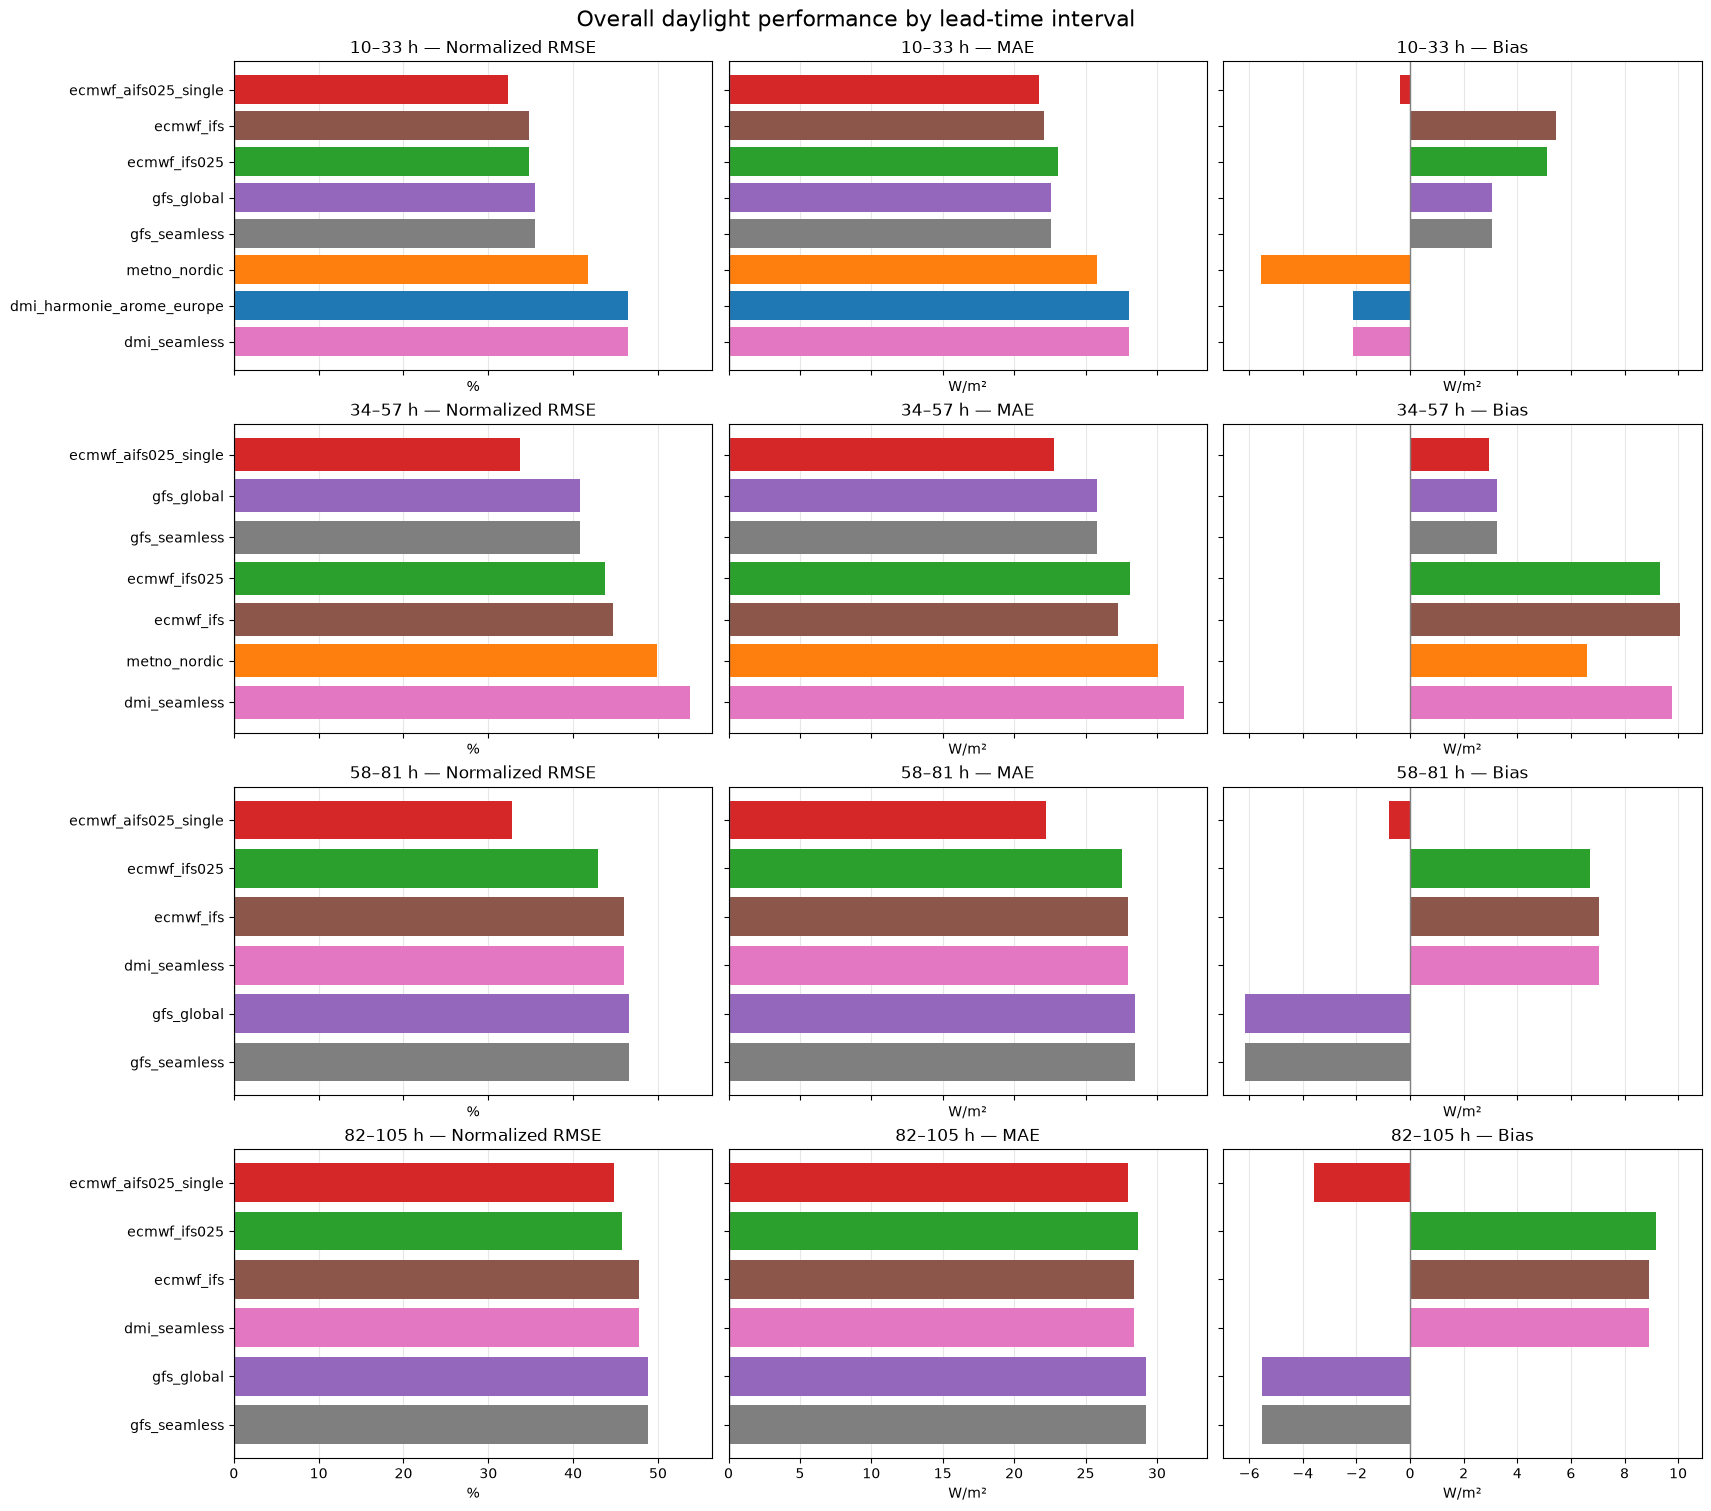

In [162]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define the lead-time intervals
intervals = [(10, 33), (34, 57), (58, 81), (82, 105)]

# Use daylight-filtered forecasts and optionally include the blend
models = forecast_unstacked.copy()
# models["blend"] = blended_forecast

# Extract valid hourly measurements
measured = hourly_dmi["ghi_measured"].replace(
    [np.inf, -np.inf], np.nan
)

# Collect the metrics for each interval
results = []

for first, last in intervals:
    leads = list(range(first, last + 1))
    predictions = {}

    for model, forecast in models.items():

        # Require finite predictions at every lead time in the interval
        subset = forecast.reindex(columns=leads).replace(
            [np.inf, -np.inf], np.nan
        )

        if not subset.notna().any(axis=0).all():
            continue

        # Convert forecasts into valid-time / lead-time pairs
        subset = subset.copy()
        subset.index.name = "valid_time"
        subset.columns.name = "lead_time_h"

        predictions[model] = subset.stack().dropna()

    # Skip intervals without eligible models
    if not predictions:
        continue

    # Keep identical forecast pairs across the eligible models
    paired = pd.concat(predictions, axis=1).dropna()

    # Match each forecast pair with its measurement
    observations = measured.reindex(
        paired.index.get_level_values("valid_time")
    )
    observations.index = paired.index

    # Remove pairs without a valid measurement
    valid = observations.notna()
    paired = paired.loc[valid]
    observations = observations.loc[valid]

    if paired.empty:
        continue

    # Calculate forecast-minus-measurement errors
    errors = paired.sub(observations, axis=0)

    # Use the same normalization denominator for every model
    mean_ghi = observations.mean()

    for model in errors.columns:
        error = errors[model]
        rmse = np.sqrt(error.pow(2).mean())

        # Calculate pooled nRMSE, MAE and bias
        results.append({
            "interval": f"{first}–{last} h",
            "model": model,
            "nrmse": (
                100 * rmse / mean_ghi if mean_ghi > 0 else np.nan
            ),
            "mae": error.abs().mean(),
            "bias": error.mean(),
            "n": len(error),
        })

# Store the results for plotting and later inspection
interval_scores = pd.DataFrame(
    results,
    columns=["interval", "model", "nrmse", "mae", "bias", "n"],
)

# Define metric titles and units
metrics = [
    ("nrmse", "Normalized RMSE", "%"),
    ("mae", "MAE", "W/m²"),
    ("bias", "Bias", "W/m²"),
]

# Create one row per interval and one column per metric
fig, axes = plt.subplots(
    len(intervals), 3,
    figsize=(17, 15),
    sharex="col",
    constrained_layout=True,
)

for row, (first, last) in enumerate(intervals):
    label = f"{first}–{last} h"

    # Rank models by nRMSE and retain this order across the row
    data = interval_scores.loc[
        interval_scores["interval"] == label
    ].sort_values("nrmse")

    for col, (metric, title, unit) in enumerate(metrics):
        ax = axes[row, col]
        ax.set_title(f"{label} — {title}")
        ax.set_xlabel(unit)

        # Explain intervals without matched data
        if data.empty:
            ax.text(
                0.5, 0.5,
                "No common matched pairs",
                transform=ax.transAxes,
                ha="center",
                va="center",
            )
            ax.set_yticks([])
            continue

        # Draw bars using the global model color palette
        positions = np.arange(len(data))

        ax.barh(
            positions,
            data[metric],
            color=[colors[model] for model in data["model"]],
        )

        # Show model names only in the first column
        ax.set_yticks(positions)
        ax.set_yticklabels(
            data["model"] if col == 0 else [""] * len(data)
        )
        ax.invert_yaxis()

        # Add a zero-reference line and grid
        ax.axvline(0, color="grey", linewidth=1)
        ax.grid(axis="x", alpha=0.3)
        ax.set_axisbelow(True)

# Add the overall title and display the figure
fig.suptitle(
    "Overall daylight performance by lead-time interval",
    fontsize=16,
)

plt.show()

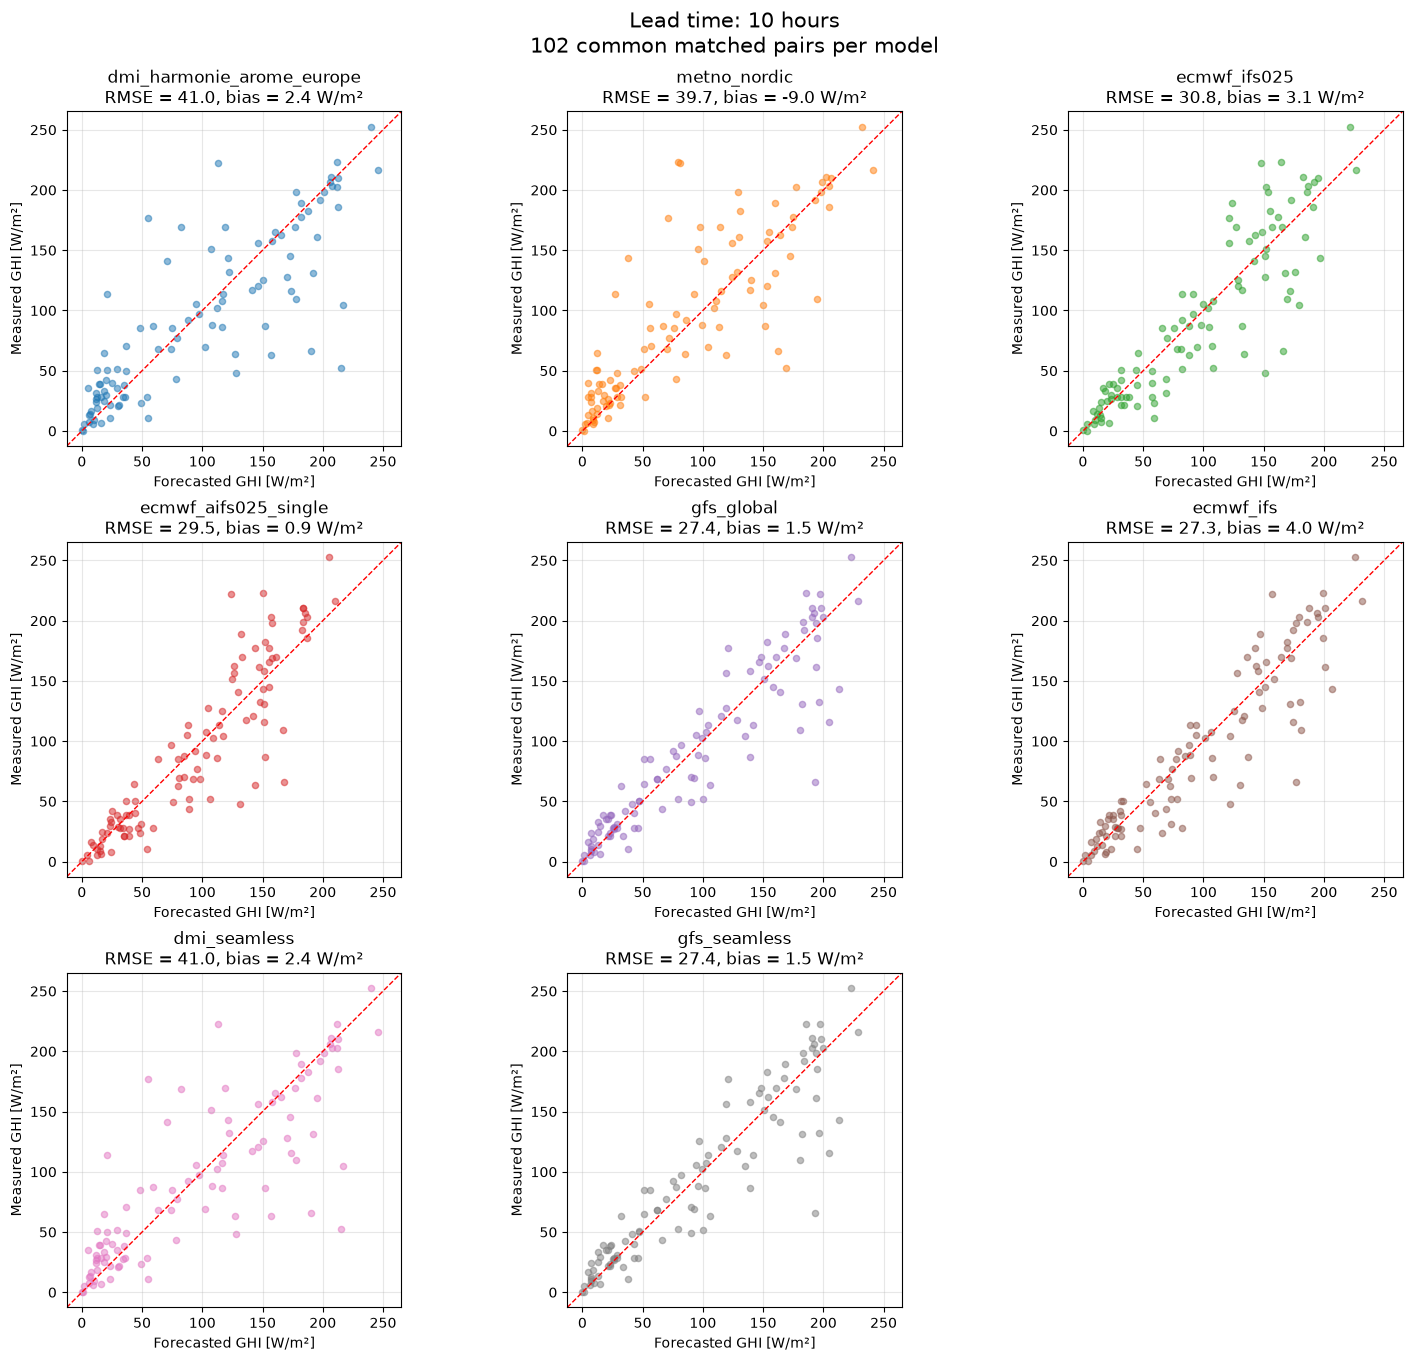

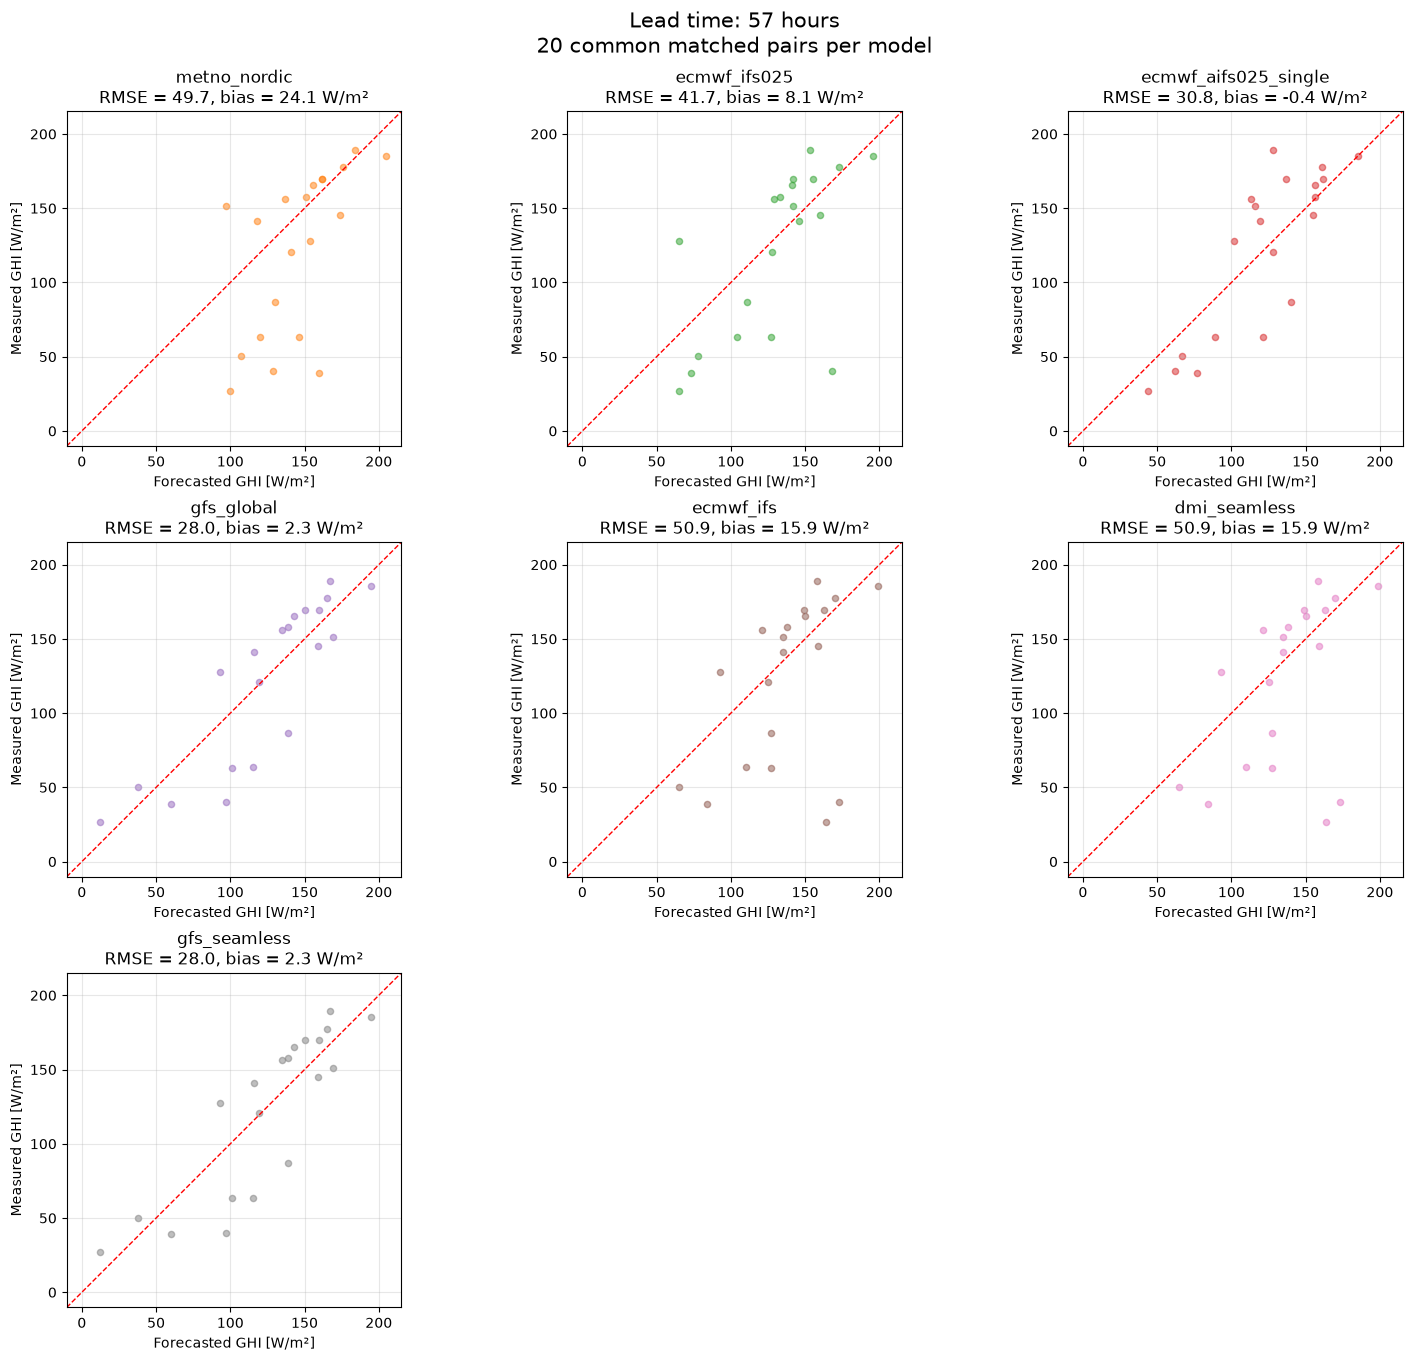

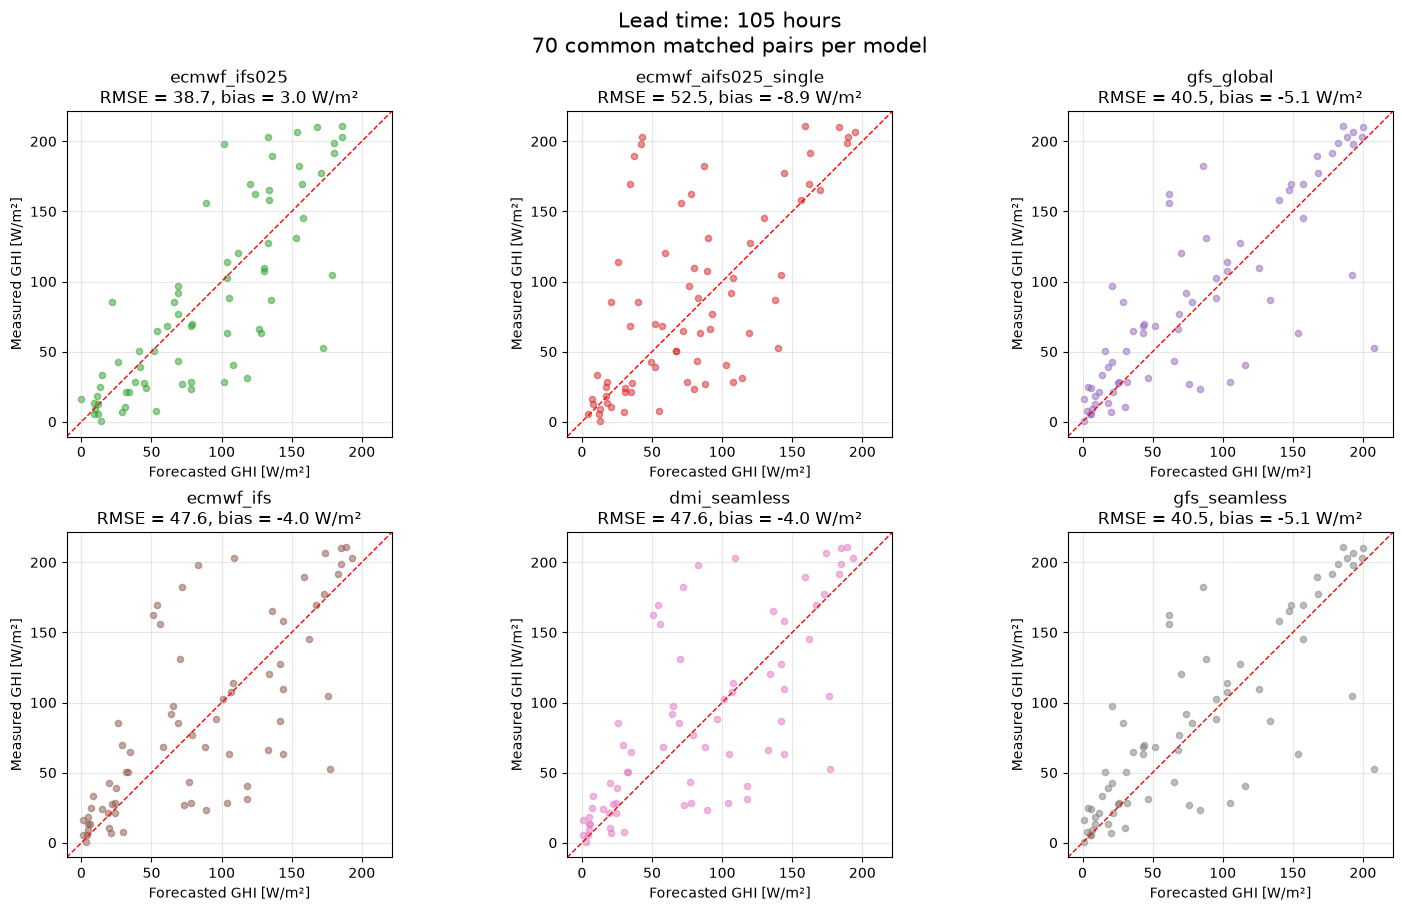

In [157]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select the three forecast horizons
lead_times = [10, 57, 105]

# Copy the forecasts and optionally include the blend
models = forecast_unstacked.copy()
# models["blend"] = blended_forecast

# Assign consistent model colors across all figures
colors = {
    model: "black" if model == "blend" else plt.get_cmap("tab10")(i % 10)
    for i, model in enumerate(models)
}

for lead in lead_times:

    # Select models with finite predictions at this lead time
    selected = {
        model: df[lead].replace([np.inf, -np.inf], np.nan).rename(model)
        for model, df in models.items()
        if lead in df.columns
    }
    selected = {
        model: values
        for model, values in selected.items()
        if values.notna().any()
    }

    # Skip horizons without available forecasts
    if not selected:
        print(f"No forecasts available at lead time {lead} hours.")
        continue

    # Match all selected models and measurements on common timestamps
    comparison = (
        pd.concat(selected.values(), axis=1)
        .join(hourly_dmi["ghi_measured"])
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    # Skip horizons without common valid observations
    if comparison.empty:
        print(f"No common matched pairs at lead time {lead} hours.")
        continue

    # Set matching axis limits for all panels in this figure
    lower = min(0, comparison.min().min())
    upper = max(1, comparison.max().max())
    padding = (upper - lower) * 0.05
    limits = (lower - padding, upper + padding)

    # Create a separate figure with only the required subplots
    ncols = min(3, len(selected))
    nrows = int(np.ceil(len(selected) / ncols))

    fig = plt.figure(
        figsize=(5 * ncols, 4.5 * nrows),
        constrained_layout=True,
    )

    for i, model in enumerate(selected):

        # Add one subplot for this model
        ax = fig.add_subplot(nrows, ncols, i + 1)

        # Calculate forecast-minus-measurement errors
        forecast = comparison[model]
        measured = comparison["ghi_measured"]
        residual = forecast - measured

        rmse = np.sqrt((residual ** 2).mean())
        bias = residual.mean()

        # Plot forecast values against measurements
        ax.scatter(
            forecast,
            measured,
            color=colors[model],
            alpha=0.5,
            s=20,
        )

        # Add the perfect-forecast reference line
        ax.plot(
            limits, limits,
            color="red",
            linestyle="--",
            linewidth=1,
        )

        # Apply identical axis scaling and label the panel
        ax.set(
            xlim=limits,
            ylim=limits,
            xlabel="Forecasted GHI [W/m²]",
            ylabel="Measured GHI [W/m²]",
            title=(
                f"{model}\n"
                f"RMSE = {rmse:.1f}, bias = {bias:.1f} W/m²"
            ),
        )
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.3)

    # Add the lead time and shared sample count
    fig.suptitle(
        f"Lead time: {lead} hours\n"
        f"{len(comparison)} common matched pairs per model",
        fontsize=15,
    )

    plt.show()

In [158]:
max_evaluated_lead = (
    scores.loc[scores["n"] > 0]
    .groupby("model")["lead_time_h"]
    .max()
)

print(max_evaluated_lead)

model
dmi_harmonie_arome_europe     56.0
dmi_seamless                 159.0
ecmwf_aifs025_single         159.0
ecmwf_ifs                    159.0
ecmwf_ifs025                 159.0
gfs_global                   159.0
gfs_seamless                 159.0
metno_nordic                  57.0
Name: lead_time_h, dtype: float64


### Different daily profiles

### Performance on different daily profiles

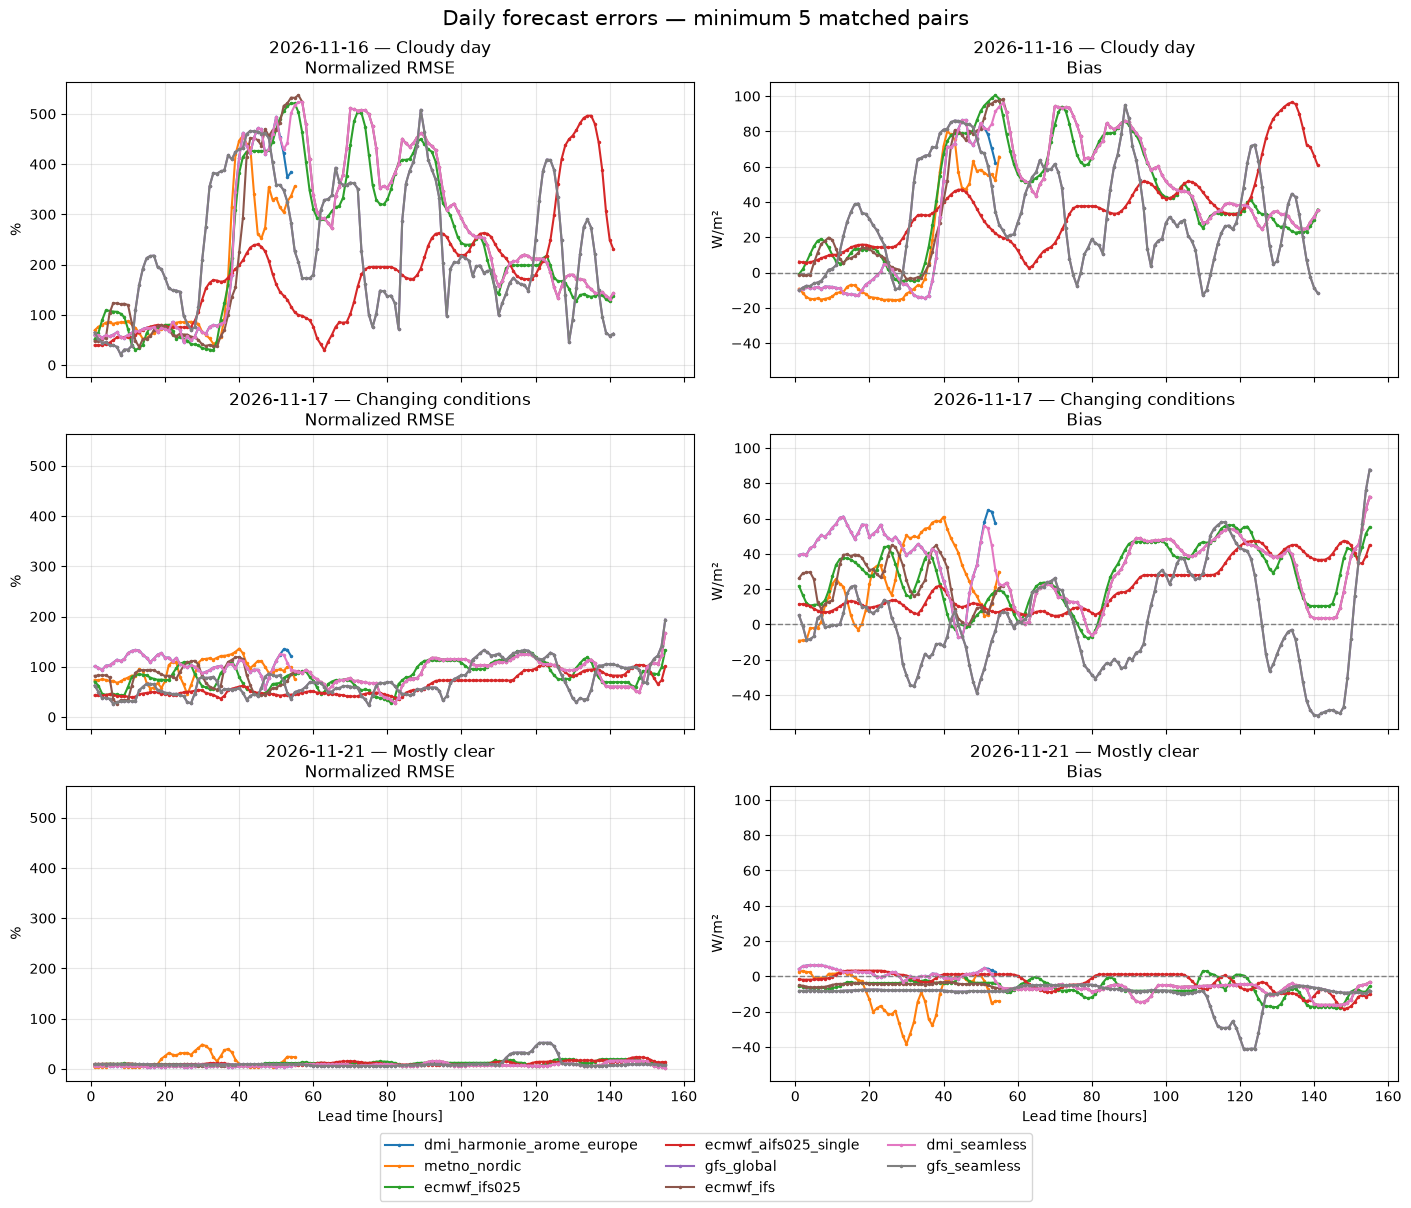

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select the daylight-filtered forecasts to evaluate
evaluation_forecasts = forecast_unstacked
# evaluation_forecasts = matched_forecasts

# Select the three daily profiles
dates = {
    "2026-11-16": "Cloudy day",
    "2026-11-17": "Changing conditions",
    "2026-11-21": "Mostly clear",
}

# Set an exploratory minimum number of matched pairs per lead time
min_daily_samples = 5

# Extract valid hourly measurements
measured = hourly_dmi["ghi_measured"].replace(
    [np.inf, -np.inf], np.nan
)

# Assign consistent model colors across all panels
colors = {
    model: "black" if model == "blend" else plt.get_cmap("tab10")(i % 10)
    for i, model in enumerate(evaluation_forecasts)
}

# Create one row per day and one column per metric
fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 12),
    sharex=True,
    sharey="col",
    constrained_layout=True,
)

# Store unfiltered daily scores for later inspection
daily_scores = {}

for row, (date, description) in enumerate(dates.items()):
    start = pd.Timestamp(date, tz="UTC")
    end = start + pd.Timedelta(days=1)
    frames = []

    for model, forecast in evaluation_forecasts.items():

        # Select right-labeled hourly intervals belonging to this UTC day
        daily_forecast = forecast.loc[
            (forecast.index > start) & (forecast.index <= end)
        ].replace([np.inf, -np.inf], np.nan)

        # Match measurements with forecast timestamps
        observations = measured.reindex(daily_forecast.index)
        errors = daily_forecast.sub(observations, axis=0)

        # Calculate mean measured GHI from the same valid pairs
        mean_measured = (
            errors.notna()
            .mul(observations, axis=0)
            .where(errors.notna())
            .mean()
        )

        # Calculate nRMSE, bias and sample count per lead time
        rmse = errors.pow(2).mean().pow(0.5)

        result = pd.DataFrame({
            "nrmse": 100 * rmse / mean_measured.where(mean_measured > 0),
            "bias": errors.mean(),
            "n": errors.count(),
        })

        # Exclude lead zero and identify the model
        result.index.name = "lead_time_h"
        result = result.loc[result.index >= 1]
        result["model"] = model
        frames.append(result.reset_index())

    # Save results before filtering them for display
    daily_scores[date] = pd.concat(frames, ignore_index=True)
    plot_data = daily_scores[date].copy()

    # Hide metrics based on too few matched pairs
    plot_data.loc[
        plot_data["n"] < min_daily_samples,
        ["nrmse", "bias"],
    ] = np.nan

    # Plot nRMSE on the left and bias on the right
    for col, (metric, title, unit) in enumerate([
        ("nrmse", "Normalized RMSE", "%"),
        ("bias", "Bias", "W/m²"),
    ]):
        ax = axes[row, col]

        # Draw one curve per model
        for model, data in plot_data.groupby("model", sort=False):
            data = data.sort_values("lead_time_h")

            ax.plot(
                data["lead_time_h"],
                data[metric],
                label=model,
                color=colors[model],
                linewidth=2.5 if model == "blend" else 1.5,
                marker=".",
                markersize=3,
            )

        # Add panel labels and grid
        ax.set_title(f"{date} — {description}\n{title}")
        ax.set_ylabel(unit)
        ax.grid(alpha=0.3)

        # Explain panels without enough observations
        if not plot_data[metric].notna().any():
            ax.text(
                0.5, 0.5,
                "Insufficient matched pairs",
                transform=ax.transAxes,
                ha="center",
                va="center",
            )

        # Add a zero-reference line for bias
        if metric == "bias":
            ax.axhline(
                0, color="grey", linestyle="--", linewidth=1
            )

# Label the horizontal axes on the bottom row
for ax in axes[-1]:
    ax.set_xlabel("Lead time [hours]")

# Add one shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="outside lower center",
    ncol=3,
)

# Add the overall title and display the figure
fig.suptitle(
    f"Daily forecast errors — minimum {min_daily_samples} matched pairs",
    fontsize=15,
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Select the three illustrative daily profiles
dates = {
    "2026-11-16": "Low irradiance",
    "2026-11-17": "Changing conditions",
    "2026-11-21": "Mostly clear",
}

# Define the lead-time intervals to compare
intervals = [(10, 33), (34, 57), (58, 81), (82, 105)]

# Use daylight-filtered forecasts and optionally include the blend
models = forecast_unstacked.copy()
# models["blend"] = blended_forecast

# Extract valid measurements
measured = hourly_dmi["ghi_measured"].replace(
    [np.inf, -np.inf], np.nan
)

# Store the tables for later use
rmse_tables = {}
sample_tables = {}

for date, description in dates.items():
    start = pd.Timestamp(date, tz="UTC")
    end = start + pd.Timedelta(days=1)

    rmse_rows = {}
    count_rows = {}

    for first, last in intervals:
        label = f"{first}–{last} h"
        predictions = {}

        for model, forecast in models.items():

            # Select this day's hourly intervals and forecast horizons
            subset = forecast.loc[
                (forecast.index > start) & (forecast.index <= end),
                (forecast.columns >= first) & (forecast.columns <= last),
            ].replace([np.inf, -np.inf], np.nan)

            # Convert predictions into valid-time / lead-time pairs
            subset = subset.copy()
            subset.index.name = "valid_time"
            subset.columns.name = "lead_time_h"
            values = subset.stack().dropna()

            if not values.empty:
                predictions[model] = values

        if not predictions:
            continue

        # Retain identical forecast pairs across the available models
        paired = pd.concat(predictions, axis=1).dropna()

        # Match each pair with its measured GHI
        observations = measured.reindex(
            paired.index.get_level_values("valid_time")
        )
        observations.index = paired.index

        # Remove pairs without a valid measurement
        valid = observations.notna()
        paired = paired.loc[valid]
        observations = observations.loc[valid]

        if paired.empty:
            continue

        # Calculate pooled RMSE directly from individual errors
        errors = paired.sub(observations, axis=0)
        rmse_rows[label] = errors.pow(2).mean().pow(0.5)
        count_rows[label] = errors.count()

    # Arrange lead-time intervals as rows and models as columns
    table = pd.DataFrame(rmse_rows).T.reindex(
        index=[f"{a}–{b} h" for a, b in intervals],
        columns=list(models),
    )
    counts = pd.DataFrame(count_rows).T.reindex(
        index=table.index,
        columns=table.columns,
    )

    rmse_tables[date] = table
    sample_tables[date] = counts

    # Display RMSE and highlight the lowest value in each interval
    print(f"\n{date} — {description}: RMSE [W/m²]")
    display(
        table.style
        .format("{:.1f}", na_rep="—")
        .highlight_min(axis=1, color="lightgreen")
    )

    # # Display the number of matched pairs supporting each result
    # print("Number of matched forecast–measurement pairs:")
    # display(counts.style.format("{:.0f}", na_rep="—"))


2026-11-16 — Low irradiance: RMSE [W/m²]


,dmi_harmonie_arome_europe,metno_nordic,ecmwf_ifs025,ecmwf_aifs025_single,gfs_global,ecmwf_ifs,dmi_seamless,gfs_seamless
10–33 h,14.9,15.9,12.1,20.2,40.6,13.6,14.9,40.6
34–57 h,83.1,69.5,84.9,41.1,88.1,83.1,85.0,88.1
58–81 h,—,—,80.0,29.6,57.4,88.0,88.0,57.4
82–105 h,—,—,76.9,48.4,65.4,81.2,81.2,65.4



2026-11-17 — Changing conditions: RMSE [W/m²]


,dmi_harmonie_arome_europe,metno_nordic,ecmwf_ifs025,ecmwf_aifs025_single,gfs_global,ecmwf_ifs,dmi_seamless,gfs_seamless
10–33 h,70.3,54.9,51.1,29.4,34.9,54.3,70.3,34.9
34–57 h,64.3,68.3,45.8,30.4,38.2,48.9,62.1,38.2
58–81 h,—,—,38.0,28.7,36.9,42.7,42.7,36.9
82–105 h,—,—,62.2,40.0,44.6,62.2,62.2,44.6



2026-11-21 — Mostly clear: RMSE [W/m²]


,dmi_harmonie_arome_europe,metno_nordic,ecmwf_ifs025,ecmwf_aifs025_single,gfs_global,ecmwf_ifs,dmi_seamless,gfs_seamless
10–33 h,6.6,31.5,10.3,10.9,10.0,6.5,6.6,10.0
34–57 h,6.5,21.9,11.2,10.5,10.5,7.3,6.6,10.5
58–81 h,—,—,13.7,14.2,7.1,10.0,10.0,7.1
82–105 h,—,—,13.2,10.2,9.8,11.2,11.2,9.8


### Build our forecast 

In [163]:
# Define an initial candidate schedule for validation
weight_schedule = [
    (10, 33, {
        "ecmwf_aifs025_single": 0.8,
        "ecmwf_ifs025": 0.2,
    }),
    (34, 57, {
        "ecmwf_aifs025_single": 0.8,
        "gfs_global": 0.2,
    }),
    (58, 81, {
        "ecmwf_aifs025_single": 0.8,
        "ecmwf_ifs025": 0.2,
    }),
    (82, 105, {
        "ecmwf_aifs025_single": 0.7,
        "ecmwf_ifs025": 0.3,
    }),
]



blended_forecast = our_blend_by_lead_time(
    forecast_unstacked,
    weight_schedule,
)

In [164]:
# Modeller og blend, som skal sammenlignes
comparison = {
    **forecast_unstacked,
    "blend": blended_forecast,
}

# Fælles tidspunkter og lead times
common_index = blended_forecast.index
common_columns = blended_forecast.columns

for df in comparison.values():
    common_index = common_index.intersection(df.index)
    common_columns = common_columns.intersection(df.columns)

aligned = {
    model: df.reindex(
        index=common_index,
        columns=common_columns,
    ).replace([np.inf, -np.inf], np.nan)
    for model, df in comparison.items()
}

# Behold kun par, hvor alle modeller og blend har en værdi
common_mask = aligned["blend"].notna()

for df in aligned.values():
    common_mask &= df.notna()

matched_forecasts = {
    model: df.where(common_mask)
    for model, df in aligned.items()
}

# Samme målinger bruges til alle modeller
comparison_scores = functions.calculate_forecast_metrics(
    matched_forecasts,
    hourly_dmi,
)

overall_comparison = functions.calculate_overall_metrics(
    comparison_scores
).sort_values("rmse")

display(overall_comparison)

,model,rmse,bias,mae,n
0,blend,29.824499,1.758559,21.744736,4461
3,ecmwf_aifs025_single,30.549664,1.141747,22.237092,4461
6,gfs_global,35.360695,3.105432,24.113353,4461
7,gfs_seamless,35.360695,3.105432,24.113353,4461
5,ecmwf_ifs025,36.001746,6.913547,25.261003,4461
4,ecmwf_ifs,36.294228,7.411417,24.295151,4461
8,metno_nordic,42.203196,-0.368677,27.653516,4461
2,dmi_seamless,46.098801,3.107170,29.750897,4461
1,dmi_harmonie_arome_europe,46.608397,3.181648,30.080401,4461


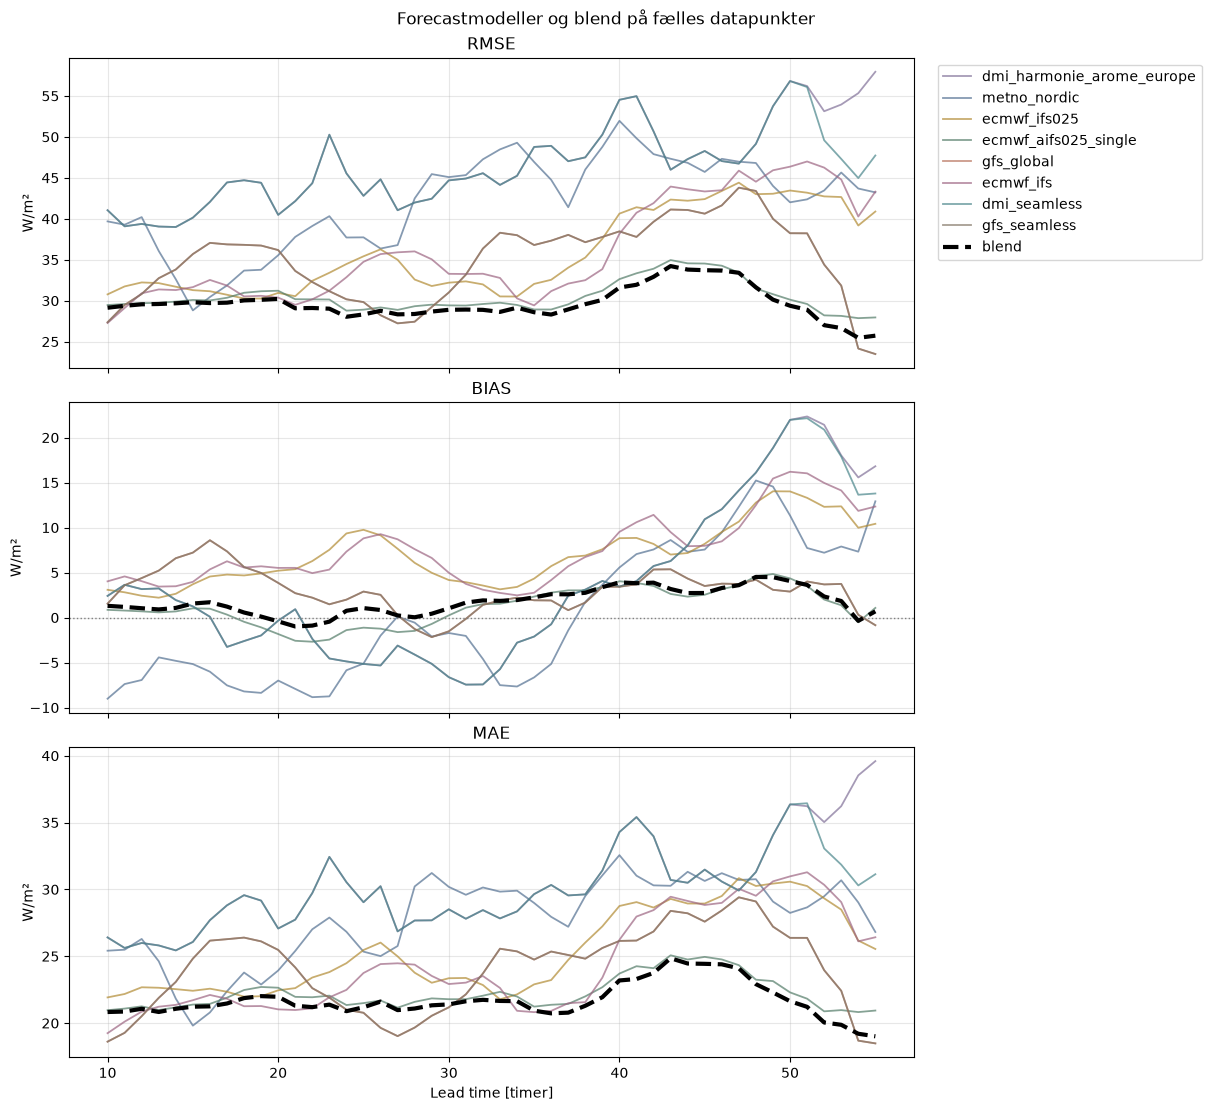

In [165]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 11),
    sharex=True,
    constrained_layout=True,
)

for ax, metric in zip(axes, ["rmse", "bias", "mae"]):
    for model, data in comparison_scores.groupby("model", sort=False):
        data = data.sort_values("lead_time_h")
        is_blend = model == "blend"

        ax.plot(
            data["lead_time_h"],
            data[metric],
            label=model,
            color="black" if is_blend else None,
            linewidth=3 if is_blend else 1.3,
            linestyle="--" if is_blend else "-",
            alpha=1 if is_blend else 0.7,
            zorder=10 if is_blend else 2,
        )

    ax.set_title(metric.upper())
    ax.set_ylabel("W/m²")
    ax.grid(alpha=0.3)

    if metric == "bias":
        ax.axhline(0, color="grey", linestyle=":", linewidth=1)

axes[-1].set_xlabel("Lead time [timer]")
axes[0].legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

fig.suptitle("Forecastmodeller og blend på fælles datapunkter")
plt.show()